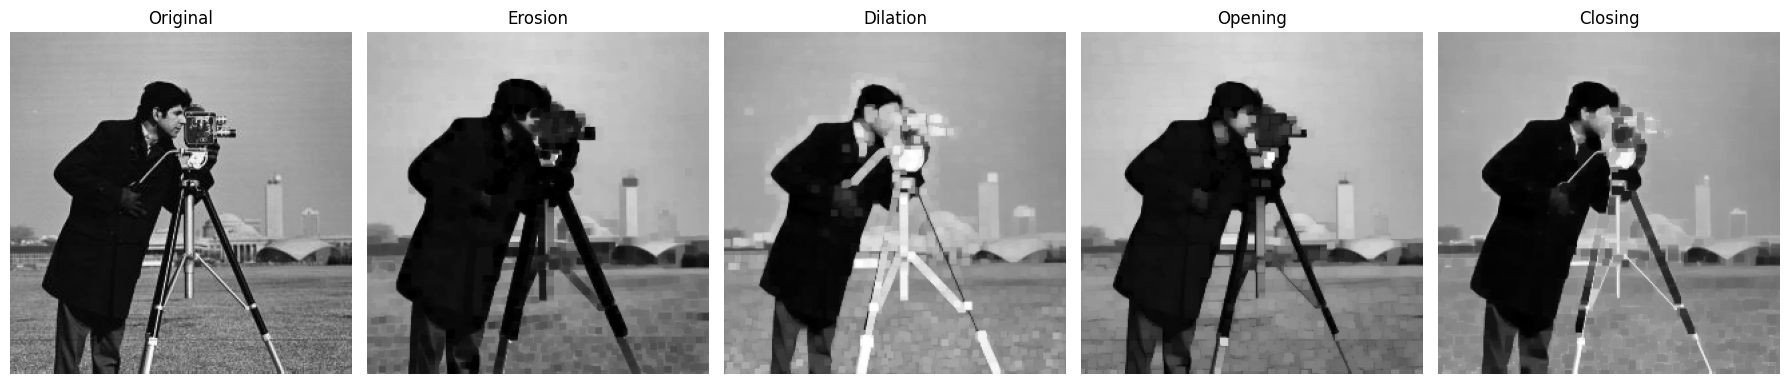

In [ ]:
    import cv2
    import matplotlib.pyplot as plt
    import numpy as np
    from pathlib import Path

    # Load the image from the same directory as the notebook.
    image_path = Path("cameraman.jpg")
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not load image: {image_path.resolve()}")

    # Define the kernel (structuring element).
    kernel = np.ones((5, 5), np.uint8)

    # Perform erosion, dilation, opening, and closing.
    erosion = cv2.erode(image, kernel, iterations=1)
    dilation = cv2.dilate(image, kernel, iterations=1)
    opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
    closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

    # Display the original image and the results in the notebook.
    results = [("Original", image), ("Erosion", erosion), ("Dilation", dilation),
            ("Opening", opening), ("Closing", closing)]
    fig, axes = plt.subplots(1, len(results), figsize=(18, 4))
    for axis, (title, result) in zip(axes, results):
        axis.imshow(result, cmap="gray")
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()